## Module 3: Computational Drug Discovery Project


## Project Goal:

 We (Makayla Bateman and Malcolm Epstein) are Quantitative Systems Pharmacologists at the UVA Manning Institute for Biotechnology in Fontaine Research Park working on a new weight loss drug Cavalitide. Obesity is a chronic condition associated with rapid fat accumulation that poses a health risk(1).
 
 The goal of our project is to test how Cavalitide competes with a Semiglutide weight loss drug. We will test our product with three different tasks: 

* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide and compare with the Semaglutide binding

* Task 2: Simulate the pharmacokinetics of Cavalitide treatment

* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:

According to the WHO, 940 million adults and 170 million children (aged 5-19) were obese in 2024 (1). The cause of obesity can be attributed to environmental, social, biological, or behavioral factors (1). Obesity is diagnosed using body mass index, a measure of weight relative to height, compared with the WHO reference chart (1). It is defined as a BMI greater than or equal to 30 in adults and weight greater than 2 standard deviations in children 5-19 (1). If the patient's weight isn't managed, their health can decline significantly(diabetes, heart problems, shortness of breath, etc.) as a result (2). Until the development of GLP-1 weight-loss medications, patients were treated with diet and exercise. GLP1s are more expensive, with some low-end plans costing $129 per month without insurance (3).

Obesity is much more prevalent in low-income areas than well-developed areas (4). The current cost of treatment is high, and many may not be able to afford the GLP1 medications currently on the market. Thus, a cheaper yet still effective alternative is paramount to helping these patients.

## Task 1: Fit a receptor binding model for Cavalitide:

Our colleague identified a molecule (Cavalitide), and performed experiments to test how well it could bind to the GLP1 receptor. Now, we aim to develop a pharmacodynamics model comparing how Semaglutide and Cavalitide are able to bind and activate the GLP1 receptor. Our model was created by achieving 3 milestones:

a)	Adaptation of previous code from modeling semaglutide to fit Cavalitide binding data.


b)	Create a plot showing [Cavalitide] vs. Fraction Active Receptors (Fact) demonstrates a good fit.


c)	Provide the fitted value of Kd for Cavalitide. Interpret Kd of Cavalitide vs. Kd of Semaglutide and explain if this is a disadvantage or advantage.

## Part a) Adapted Code

Adapted code for Cavalitide binding data. Changes in the original code was the name of the CSV file to load data from, labels and title on graph, and finally the addition of a comparison code to test quantitatively the difference in efficacy of the Cavalitide to Semaglutide.

Brute-force Kd2 = 0.0771 nM (SSE = 0.0052)
Curve_fit Kd2 = 0.0770 +/- 0.0045 nM (SSE = 0.0052)
Cavalitide binds ~4.45 times more tightly than semaglutide


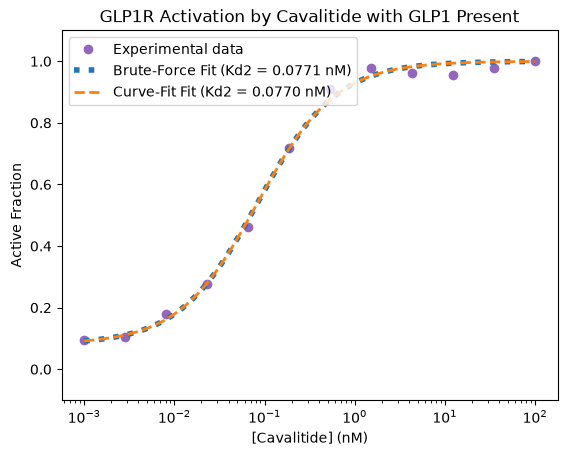

In [7]:
# Import packages needed for Task 1
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Create model
def Fact(L1, L2, Kd1, Kd2):
    """Fraction of active receptors with two agonists competing for one receptor.
    L1, Kd1 = GLP1 (natural ligand); L2, Kd2 = Cavalitide (drug being tested)"""
    return (Kd2*L1 + Kd1*L2)/(Kd1*Kd2 + Kd2*L1 + Kd1*L2) 

# State known parameters
Kd1 = .17                                                               # GLP1 dissociation constant [nM]
L1 = .015                                                               # Concentration of the first ligand, GLP1 after fasting [nM]
L2 = np.logspace(-3, 2 ,500)                                            # Array of 500 Cavalitide concentrations between .001 and 100 nM, smoothes model curve
# Kd2 = variable we're solving for

# Load the data into the file
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)     # Load data set, comma separations, skip first header row
L2_loaded, Fact_loaded = data[:,0], data[:,1]                           # Separates L2 (Cavalitide concentrations) and active fraction of drug

# Approach 1, brute force optimization of Kd2
Kd2_candidates = np.logspace(-3, 2, 1000)                               # 1000 candidate Kd values between .001 and 100 nM
SSE_brute = np.inf                                                      # starts best error at infinity
for Kd2_test in Kd2_candidates:
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_test))**2) # Sum of squared errors formula
    if SSE < SSE_brute:                                                 # If new SSE is lower than initial SSE, that is saved with its Kd
        SSE_brute = SSE
        Kd2_brute = Kd2_test                                            # Lowest SSE is saved into Kd2_brute
print(f"Brute-force Kd2 = {Kd2_brute:.4f} nM (SSE = {SSE_brute:.4f})")  # Prints lowest SSE Kd

# Approach 2, curve fit of Kd2
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),          # L2_loaded is x, Fact_loaded is y
                       L2_loaded, Fact_loaded, p0=[.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
Kd2_error = np.sqrt(pcov[0,0])                                          # Find error of measurement
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Curve_fit Kd2 = {Kd2_fit:.4f} +/- {Kd2_error:.4f} nM (SSE = {SSE_fit:.4f})")

# Compare data from Cavalitide Kd with Semaglutide Kd
Kd_semabrute = .335                                                     # Values obtained from fit_semaglutide_GLP1R.py file Approach 1
Kd_semabrute_SSE = .0047                                                # Values obtained from fit_semaglutide_GLP1R.py file Approach 1
Cav_vs_sema_brute = (Kd_semabrute / Kd2_fit)                            # Find ratio of Cavalitide Kd to Semaglutide Kd from brute-force approach

Kd_semacurvefit = .350                                                  # Values obtained from fit_semaglutide_GLP1R.py file Approach 2
Kd_semacurvefit_SSE = .0044                                             # Values obtained from fit_semaglutide_GLP1R.py file Approach 2
Cav_vs_sema_curvefit = (Kd_semacurvefit / Kd2_fit)                      # Find ratio of Cavalitide Kd to Semaglutide Kd from curve-fit approach

Cav_vs_sema_avg = (Cav_vs_sema_brute + Cav_vs_sema_curvefit) / 2        # Take and print average of two approaches
print(f"Cavalitide binds ~{Cav_vs_sema_avg:.2f} times more tightly than semaglutide")

# Plot data and model fits to create figure for data
plt.figure()                                                            # Create empty figure
plt.semilogx(L2_loaded, Fact_loaded, "o", c="tab:purple",
            label="Experimental data")                                  # Plots measured points with circle markers
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=4,
             label=f"Brute-Force Fit (Kd2 = {Kd2_brute:.4f} nM)")       # Plots model curve with brute-force Kd
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"Curve-Fit Fit (Kd2 = {Kd2_fit:.4f} nM)")           # Plots model curve with curve-fit Kd
plt.ylim(-.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Active Fraction")
plt.title("GLP1R Activation by Cavalitide with GLP1 Present")
plt.legend(loc="upper left")
plt.show()                                                              # Create plot with above criteria

## Part b) Plot of [Cavalitide] vs. Active Fraction

The Brute-Force Fit and Curve-Fit lines are right on top of each other meaning they are approximately the same fits. The curve provided by these two fits are very close to the experimental data point curve. There are no major outliers shown on the graph and all points are within .05 away from the fit line. Therefore, the [Cavalitide] models demonstrate a good fit.

* At 1 nM concentration of Cavalitide, approximately 90% of GLP1 receptors are active and bound to the molecule.

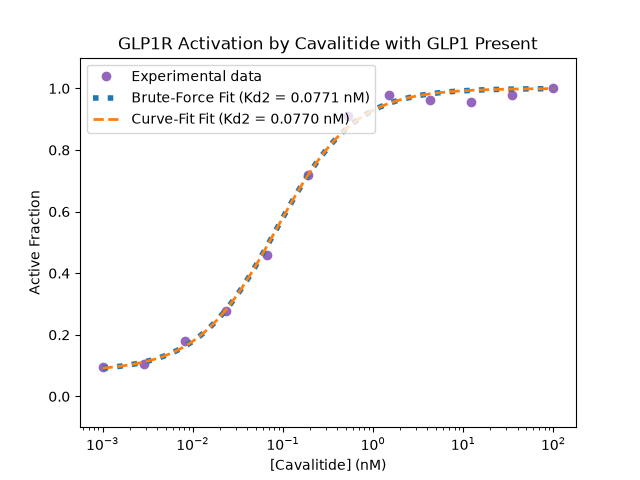

Fig.1. Plot of [Cavalitide] vs. Active Fraction (Fact)

## Part c) Interpretation of Kd value for Cavalitide

Lower Kd (dissociation constant) means there is a higher affinity for binding and the bond will be tighter between ligand and receptor. Cavalitide has a Kd of ~.0771 and Semaglutide has a Kd ~.3475. The Kd for Cavalitide is smaller than for Semaglutide meaning it will bind more tightly to the receptor and be more potent at a lower dosage. Thus, an advantage of Cavalitide vs Semaglutide is more effective weight loss potential for patients. To determine how much more tightly the Cavalitide binds than Semaglutide, I divided the brute Kd of Semaglutide by the Kd fit of Cavalitide. Then I divided the curve fit Kd of Semaglutide by the Kd fit of Cavalitide. Finally, I added the two ratios together and divided by two to find that Cavalitide binds 4.45 times more tightly than Semaglutide does.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

1) Simulations for Ozempic and Wegovy. Euler's method is replaced with scipy.integrate.solve_ivp and plots created for both. Also created a graph comparing the semiglutide in blood between the two. The graphs show large spikes in Ozempic blood concentrations which makes sense for a direct injection. Wegovy has more consistent and frequent increases which lines up for a daily tablet.

Ozempic: max free [semaglutide] = 0.679 nM, free [semaglutide] at end = 0.494 nM
Wegovy: max free [semaglutide] = 0.599 nM, free [semaglutide] at end = 0.599 nM


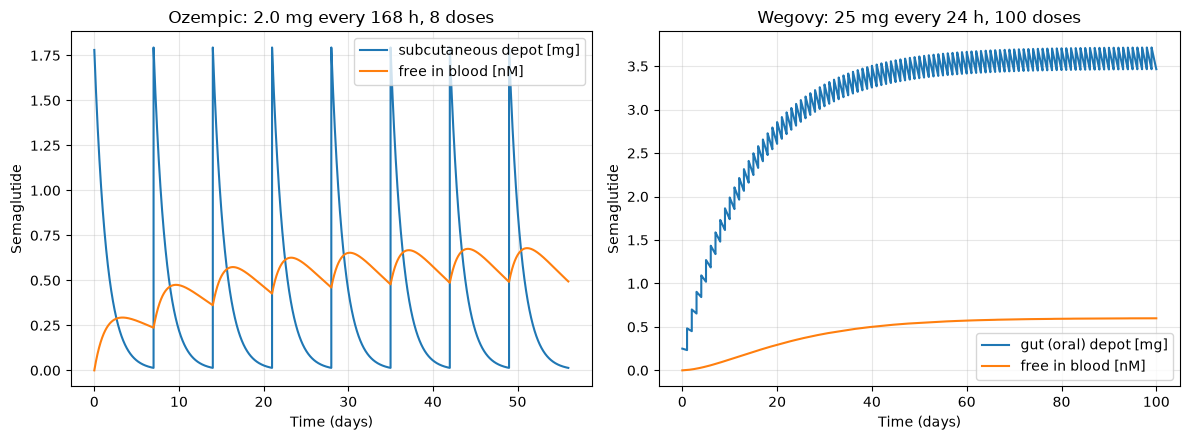

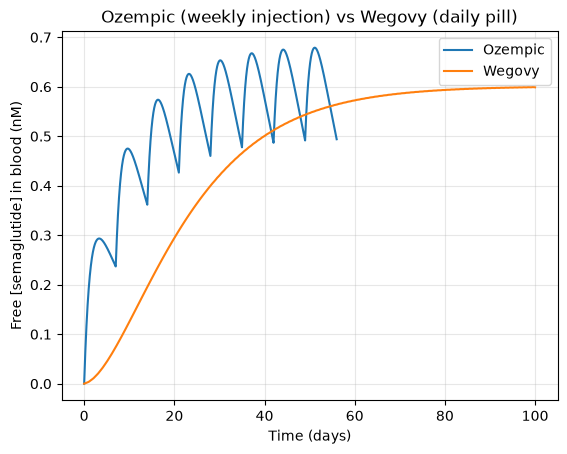

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,              # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}

# Shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # fraction free
dt = 0.1        # h, spacing of output time points

# ODE model, ka is passed in as an argument
def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

# Dosing simulation using solve_ivp
def simulate(Favailable, ka, D, interval, n_doses):
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    for i in range(n_doses):
        y[0] += Favailable*D                                  # the absorbed fraction of the dose enters the depot
        t0, t1 = i*interval, (i + 1)*interval
        t_eval = np.linspace(t0, t1, int(round(interval/dt)) + 1)
        sol = solve_ivp(ODEfunc, (t0, t1), y, args=(ka,), t_eval=t_eval,
                        method="LSODA", rtol=1e-8, atol=1e-10)  # integrate over one dosing interval
        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()                               # carry the current state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / MW * 1e9          
    return t, Asc_out, Cc_nM

# Run both products
results = {}
for drug, p in products.items():
    results[drug] = simulate(p['Favailable'], p['ka'], p['D'], p['interval'], p['n_doses'])
    t, Asc, Cc = results[drug]
    print(f"{drug}: max free [semaglutide] = {Ffree*Cc.max():.3f} nM, "
          f"free [semaglutide] at end = {Ffree*Cc[-1]:.3f} nM")
    
# Plot both products
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (drug, p) in zip(axes, products.items()):
    t, Asc, Cc = results[drug]
    ax.plot(t/24, Asc, label=f"{p['depot']} depot [mg]")
    ax.plot(t/24, Ffree*Cc, label="free in blood [nM]")
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Semaglutide")
    ax.set_title(f"{drug}: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("semaglutidePK_products.png", dpi=200)

# Comparison of free blood concentration
plt.figure()
for drug in products:
    t, Asc, Cc = results[drug]
    plt.plot(t/24, Ffree*Cc, label=drug)
plt.xlabel("Time (days)")
plt.ylabel("Free [semaglutide] in blood (nM)")
plt.title("Ozempic (weekly injection) vs Wegovy (daily pill)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("semaglutidePK_comparison.png", dpi=200)
plt.show()

2) Now the code is changed to adapt semaglutidePK.py to incorporate simulations of Cavalitide. A new graph is plotted for Cavalitide on its own, as well as a blood concentration comparison between the three drugs. While all three drugs reach 60% free drug in blood, cavalatide does so without fluctuation and earlier than Wegovy.

Ozempic: free conc at end = 0.494 nM, max = 0.679 nM, reaches 90% of final level by day 8
Wegovy: free conc at end = 0.599 nM, max = 0.599 nM, reaches 90% of final level by day 48
Cavalitide: free conc at end = 0.600 nM, max = 0.601 nM, reaches 90% of final level by day 34


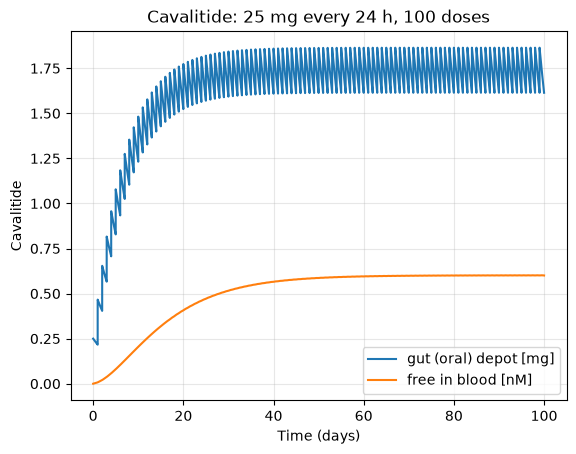

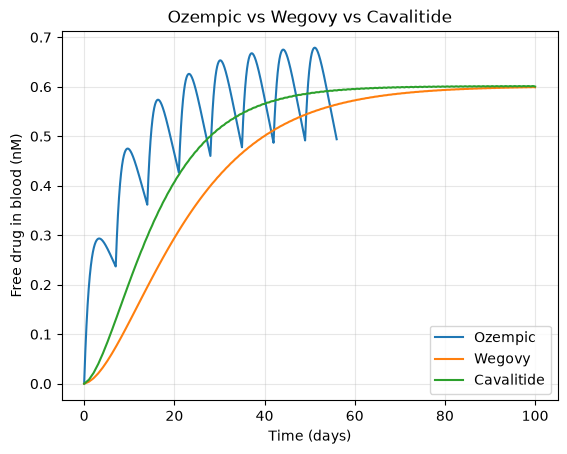

In [9]:
# Add Cavalitide to the products dictionary
products['Cavalitide'] = dict(Favailable=0.01,   # assumed same as Wegovy
                              ka=0.006,          # 1/h, increased absorption rate
                              D=25,              # mg, same starting dose as Wegovy
                              interval=24,       # h between doses
                              n_doses=100,
                              depot='gut (oral)')

# Step 2: Simulate all three products
results = {}
for drug, p in products.items():
    results[drug] = simulate(p['Favailable'], p['ka'], p['D'], p['interval'], p['n_doses'])
    t, Asc, Cc = results[drug]
    free = Ffree*Cc
    t_90 = t[np.argmax(free >= 0.9*free[-1])]/24              # days to reach 90% of final amount
    print(f"{drug}: free conc at end = {free[-1]:.3f} nM, max = {free.max():.3f} nM, "
          f"reaches 90% of final level by day {t_90:.0f}")

# Plot Cavalitide depot and blood concentration over time
t, Asc, Cc = results['Cavalitide']
p = products['Cavalitide']
plt.figure()
plt.plot(t/24, Asc, label=f"{p['depot']} depot [mg]")
plt.plot(t/24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"Cavalitide: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Step 4: Compare free blood concentration of all three products
plt.figure()
for drug in products:
    t, Asc, Cc = results[drug]
    plt.plot(t/24, Ffree*Cc, label=drug)
plt.xlabel("Time (days)")
plt.ylabel("Free drug in blood (nM)")
plt.title("Ozempic vs Wegovy vs Cavalitide")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

3) To optimize the dosing strategy at 0.5 nM, we changed the dose from 25mg to 21mg per pill. This resulted in a blood concentration of about 0.504 nM which is extremely close to the target value.

Optimized Cavalitide: 21 mg every 24 h -> free conc at day 100 = 0.504 nM (target = 0.5 nM)


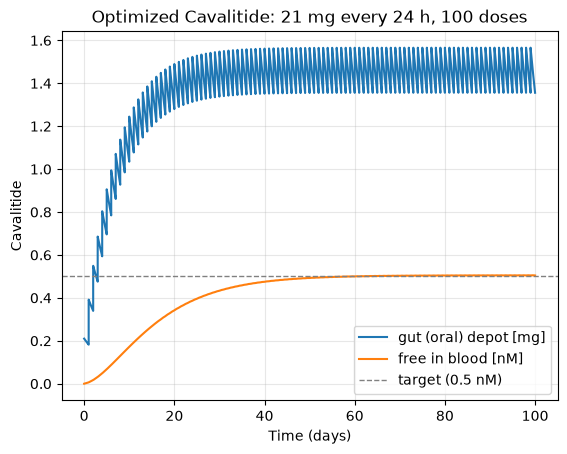

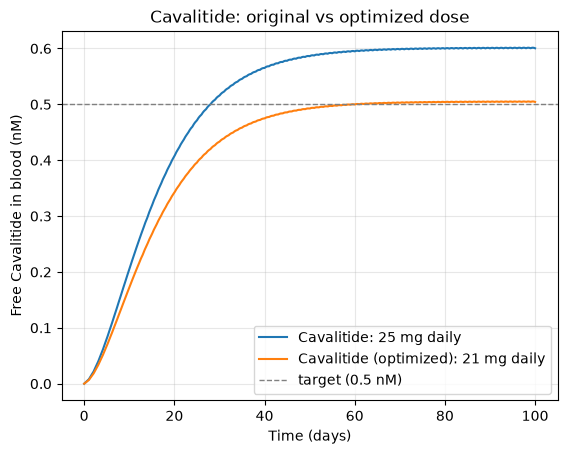

In [10]:
# Step 1: Optimized Cavalitide dosing
target = 0.5                                     # nM, target free steady state concentration
products['Cavalitide (optimized)'] = dict(Favailable=0.01,
                                          ka=0.006,          # 1/h
                                          D=21,              # mg, changed from 25
                                          interval=24,       # h
                                          n_doses=100,
                                          depot='gut (oral)')

# Step 2: Simulate optimized dosing
p = products['Cavalitide (optimized)']
results['Cavalitide (optimized)'] = simulate(p['Favailable'], p['ka'], p['D'], p['interval'], p['n_doses'])
t, Asc, Cc = results['Cavalitide (optimized)']
free = Ffree*Cc
print(f"Optimized Cavalitide: {p['D']} mg every {p['interval']} h -> "
      f"free conc at day 100 = {free[-1]:.3f} nM (target = {target} nM)")

# Step 3: Plot optimized Cavalitide depot and blood concentration over time
plt.figure()
plt.plot(t/24, Asc, label=f"{p['depot']} depot [mg]")
plt.plot(t/24, free, label="free in blood [nM]")
plt.axhline(target, ls="--", c="gray", lw=1, label=f"target ({target} nM)")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"Optimized Cavalitide: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Step 4: Compare original and optimized Cavalitide dosing
plt.figure()
for drug in ['Cavalitide', 'Cavalitide (optimized)']:
    t, Asc, Cc = results[drug]
    plt.plot(t/24, Ffree*Cc, label=f"{drug}: {products[drug]['D']} mg daily")
plt.axhline(target, ls="--", c="gray", lw=1, label=f"target ({target} nM)")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood (nM)")
plt.title("Cavalitide: original vs optimized dose")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment

1) Embedded the ligand-receptor model into the new cavalitidePK.py model. The fraction of active GLP1R receptors increases sharply before leveling out at about 87%.

Fact at day 0 (GLP1 only) = 0.081
Fact at day 100 = 0.869 (free Cavalitide = 0.504 nM)


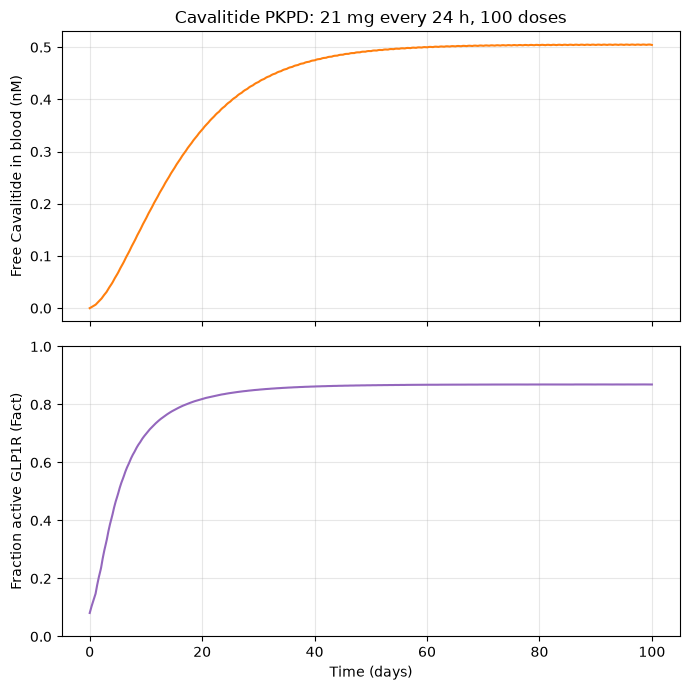

In [11]:
# Step 1: PD model from task 1
def Fact(L1, L2, Kd1, Kd2):
    return (Kd2*L1 + Kd1*L2)/(Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# PD parameters
Kd1 = 0.17          # nM, GLP1 dissociation constant
Kd2 = 0.0771        # nM, Cavalitide dissociation constant
L1 = 0.015          # nM, fasting GLP1 concentration

# PK - get free Cavalitide blood concentration over time
t, Asc, Cc = results['Cavalitide (optimized)']
p = products['Cavalitide (optimized)']
L2_blood = Ffree*Cc 

# PKPD - input the PK concentration into the PD model
Fact_t = Fact(L1, L2_blood, Kd1, Kd2)                 # fraction of active GLP1R at each time point
print(f"Fact at day 0 (GLP1 only) = {Fact_t[0]:.3f}")
print(f"Fact at day 100 = {Fact_t[-1]:.3f} (free Cavalitide = {L2_blood[-1]:.3f} nM)")

# Plot blood concentration and fraction of active receptors over 100 days
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
ax1.plot(t/24, L2_blood, c="tab:orange")
ax1.set_ylabel("Free Cavalitide in blood (nM)")
ax1.set_title(f"Cavalitide PKPD: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
ax1.grid(alpha=0.3)

ax2.plot(t/24, Fact_t, c="tab:purple")
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction active GLP1R (Fact)")
ax2.set_ylim(0, 1)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2) Now the dosing is further optimized by changing the dose per pill from 21mg to 29mg. Only changing the dose has multiple benefits. One is that the pills can remain exactly daily which is easy for patients to understand and follow. Moving up to 90% activations means a slightly stronger effect which could mean better weight loss results. Additionally, at 90%, meals have almost no effect on activation levels which means less variability for the patient.

Best daily dose = 29 mg
Fact at day 100 = 0.901 (free Cavalitide = 0.696 nM)


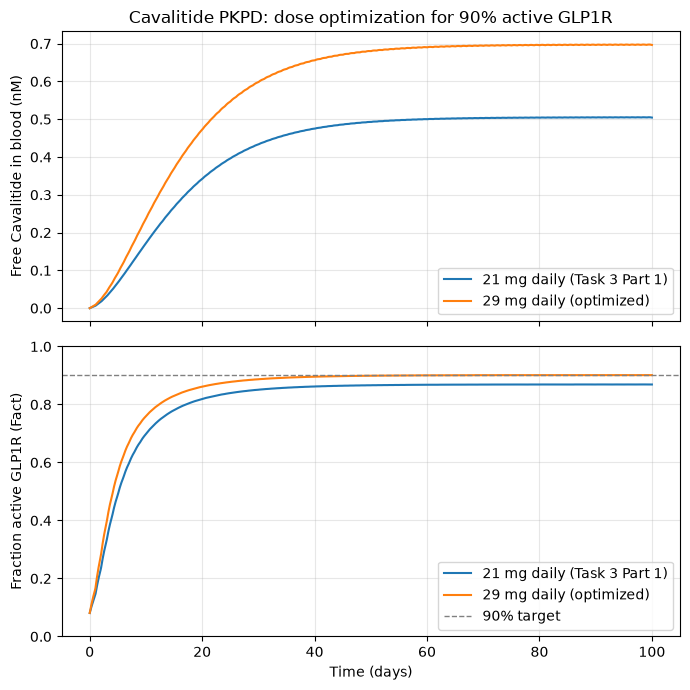

In [ ]:
# Search many daily doses to find the one closest to 90% active receptors
Fact_target = 0.90
dose_candidates = np.arange(21, 41, 1)                    # mg, whole-mg doses from 21 to 40
best_error = np.inf
for D_test in dose_candidates:
    t, Asc, Cc = simulate(0.01, 0.006, D_test, 24, 100)   
    Fact_end = Fact(L1, Ffree*Cc[-1], Kd1, Kd2)           # Fact at day 100
    error = abs(Fact_end - Fact_target)
    if error < best_error:                                # save dose closest to target
        best_error = error
        D_best = D_test
print(f"Best daily dose = {D_best} mg")

# Step 2: Simulate PKPD with the optimized dose
products['Cavalitide (PKPD optimized)'] = dict(Favailable=0.01,
                                               ka=0.006,          # 1/h
                                               D=D_best,          # mg, raised from 21 mg
                                               interval=24,       # h
                                               n_doses=100,
                                               depot='gut (oral)')
p = products['Cavalitide (PKPD optimized)']
results['Cavalitide (PKPD optimized)'] = simulate(p['Favailable'], p['ka'], p['D'], p['interval'], p['n_doses'])
t, Asc, Cc = results['Cavalitide (PKPD optimized)']
L2_blood_opt = Ffree*Cc
Fact_opt = Fact(L1, L2_blood_opt, Kd1, Kd2)
print(f"Fact at day 100 = {Fact_opt[-1]:.3f} (free Cavalitide = {L2_blood_opt[-1]:.3f} nM)")

# Step 3: Compare the 21 mg dose to the optimized dose
t21, Asc21, Cc21 = results['Cavalitide (optimized)']
Fact_21 = Fact(L1, Ffree*Cc21, Kd1, Kd2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
ax1.plot(t21/24, Ffree*Cc21, label="21 mg daily (Task 3 Part 1)")
ax1.plot(t/24, L2_blood_opt, label=f"{D_best} mg daily (optimized)")
ax1.set_ylabel("Free Cavalitide in blood (nM)")
ax1.set_title("Cavalitide PKPD: dose optimization for 90% active GLP1R")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(t21/24, Fact_21, label="21 mg daily (Task 3 Part 1)")
ax2.plot(t/24, Fact_opt, label=f"{D_best} mg daily (optimized)")
ax2.axhline(Fact_target, ls="--", c="gray", lw=1, label="90% target")
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction active GLP1R (Fact)")
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusions:

To check whether our model is realistic, we compared it to published data on semaglutide. Lau et al. (2015), the paper that first described semaglutide, measured its GLP-1 receptor binding affinity at 0.38 ± 0.06 nM (5). Our fitted Kd for semaglutide was 0.335–0.350 nM, within about 10% of the published value, which suggests our receptor binding model and fitting method are reliable.

Our analyses suggest that Cavalitide has strong potential to compete with semaglutide, especially as an oral alternative to Wegovy. In Task 1, Cavalitide’s fitted Kd was roughly 4.5 times lower than semaglutide’s which means Cavalitide binds the GLP1 receptor more tightly and activates more receptors at the same blood concentration. At about 0.6 nM free drug, Wegovy is predicted to activate only about 64% of GLP1 receptors, and Ozempic is between about 60 and 67%. Cavalitide at only 0.5 nM activates about 87%. In Task 2, Cavalitide’s higher absorption rate let it reach steady state about two weeks sooner than Wegovy. Across Tasks 2 and 3, Cavalitide’s tighter binding gave flexibility in dosing. A 21 mg daily pill reaches the 0.5 nM target using 16% less drug than Wegovy’s 25 mg, while still activating about 87% of receptors. A 29 mg daily pill gets about 90% receptor activation, which semaglutide would only reach at a much higher blood concentration. Being in oral form, Cavalitide wouldn't have Ozempic's spikes and troughs in blood concentration from direct injection. Overall, Cavalitide could offer better receptor activation than both Wegovy and Ozempic at a similar or lower oral dose, and with faster onset. This makes it a great candidate for further trials and commercial investigation. Some ethical implications of increasing the dosage per pill from 21mg to 29mg could be a higher risk of side effects and lower affordability which would affect equity for low-income patients.

## Limitations and Future Work:

The data had no patient variablilty, only one "model" patient which might not be completely accurate to real data. The data set was also quite small (only 12 points), increasing the chance for the data to be significantly skewed from a single outlier. If we had more time, we would find a larger data set to ensure our findings are accurate. Additionally, we would find and include Tirzepatide data and oral data as extra comparison points along with Semaglutide so the study is well rounded.

## AI Usage Statement:

We used Claude Code to help debug our code and check for accuracy. This was helpful in ensuring our code would run smoothly and fixing minor errors relating to typos and missed punctuation formatting in our code.

## GitHub Repository Link:
https://github.com/Athena20227876/Module-_3_Repository


## References (in order):

1. World Health Organization: WHO. (2026, October 7). Obesity and overweight. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight

2. HexaHealth. (2023, October 12). Obesity symptoms - Understand the common signs here. HexaHealth. https://www.hexahealth.com/blog/symptoms-of-obesity

3. Anthony. (2026, October 8). Cheapest GLP-1 without insurance (2026): Most affordable options ranked. CheckWeightLoss. https://checkweightloss.com/cheapest-glp1/

4. Petrov, N. (2026, July 20). Obesity and Poverty statistics. https://worldmetrics.org/obesity-and-poverty-statistics/

5. Lau, J., Bloch, P., Schäffer, L., Pettersson, I., Spetzler, J., Kofoed, J., Madsen, K., Knudsen, L. B., McGuire, J., Steensgaard, D. B., Strauss, H. M., Gram, D. X., Knudsen, S. M., Nielsen, F. S., Thygesen, P., Reedtz-Runge, S., & Kruse, T. (2015). Discovery of the once-weekly glucagon-like peptide-1 (GLP-1) analogue semaglutide. Journal of Medicinal Chemistry, 58(18), 7370–7380. https://doi.org/10.1021/acs.jmedchem.5b00726


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*